<center><h1>Satish_Manvika_HW5</h1></center>
<br>
<br>

Name: Manvika Satish
<br>
Github Username: manvsatish
<br>
USC ID: 5582061880

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
from pathlib import Path # data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt # plotting
import seaborn as sns

from sklearn.impute import SimpleImputer # preprocessing& model selection
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text # classification tree
from sklearn.metrics import accuracy_score

# regression mods
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
# boosting
from xgboost import XGBRegressor

# notebook settings
RANDOM_STATE = 552
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 150)

print("Packages imported successfully.")

Packages imported successfully.


### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
diagnosis_path = Path("../data/diagnosis.data")

#6 preds, 2 labels
diagnosis_columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]
diagnosis_raw = pd.read_csv(diagnosis_path, sep="\t", header=None, names=diagnosis_columns, encoding="utf-16", decimal=",") #tab sep utf file
print("Raw dataset shape:", diagnosis_raw.shape)
display(diagnosis_raw.head())

binary_columns = diagnosis_columns[1:] # yes/no column -> 1/0

diagnosis_data = diagnosis_raw.copy()
diagnosis_data[binary_columns] = diagnosis_data[binary_columns].replace({"no": 0, "yes": 1}).astype(int)

#verify ds before modeling
assert diagnosis_data.shape == (120, 8)
assert diagnosis_data.isna().sum().sum() == 0
assert diagnosis_data[binary_columns].isin([0, 1]).all().all()
print("Encoded dataset shape:", diagnosis_data.shape)
print("Total missing values:", diagnosis_data.isna().sum().sum())
print("\nEncoded data types:")
display(diagnosis_data.dtypes.to_frame(name="Data Type"))

print("\nFirst five encoded rows:")
display(diagnosis_data.head())

print("\nLabel combination counts:")
display(diagnosis_data[["bladder_inflammation", "nephritis"]].value_counts().sort_index().to_frame(name="Count"))

Raw dataset shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Encoded dataset shape: (120, 8)
Total missing values: 0

Encoded data types:


,Data Type
temperature,float64
nausea,int64
lumbar_pain,int64
urine_pushing,int64
micturition_pains,int64
burning_urethra,int64
bladder_inflammation,int64
nephritis,int64



First five encoded rows:


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0



Label combination counts:


Count
bladder_inflammation nephritis       
0                    0             30
                     1             31
1                    0             40
                     1             19

### (b) Build a decision tree

Label-powerset class counts:


,Count
Bladder inflammation only,40
Nephritis only,31
Neither,30
Both diagnoses,19


Tree depth: 4
Number of leaves: 6
Number of nodes: 11
Whole-dataset accuracy: 1.0


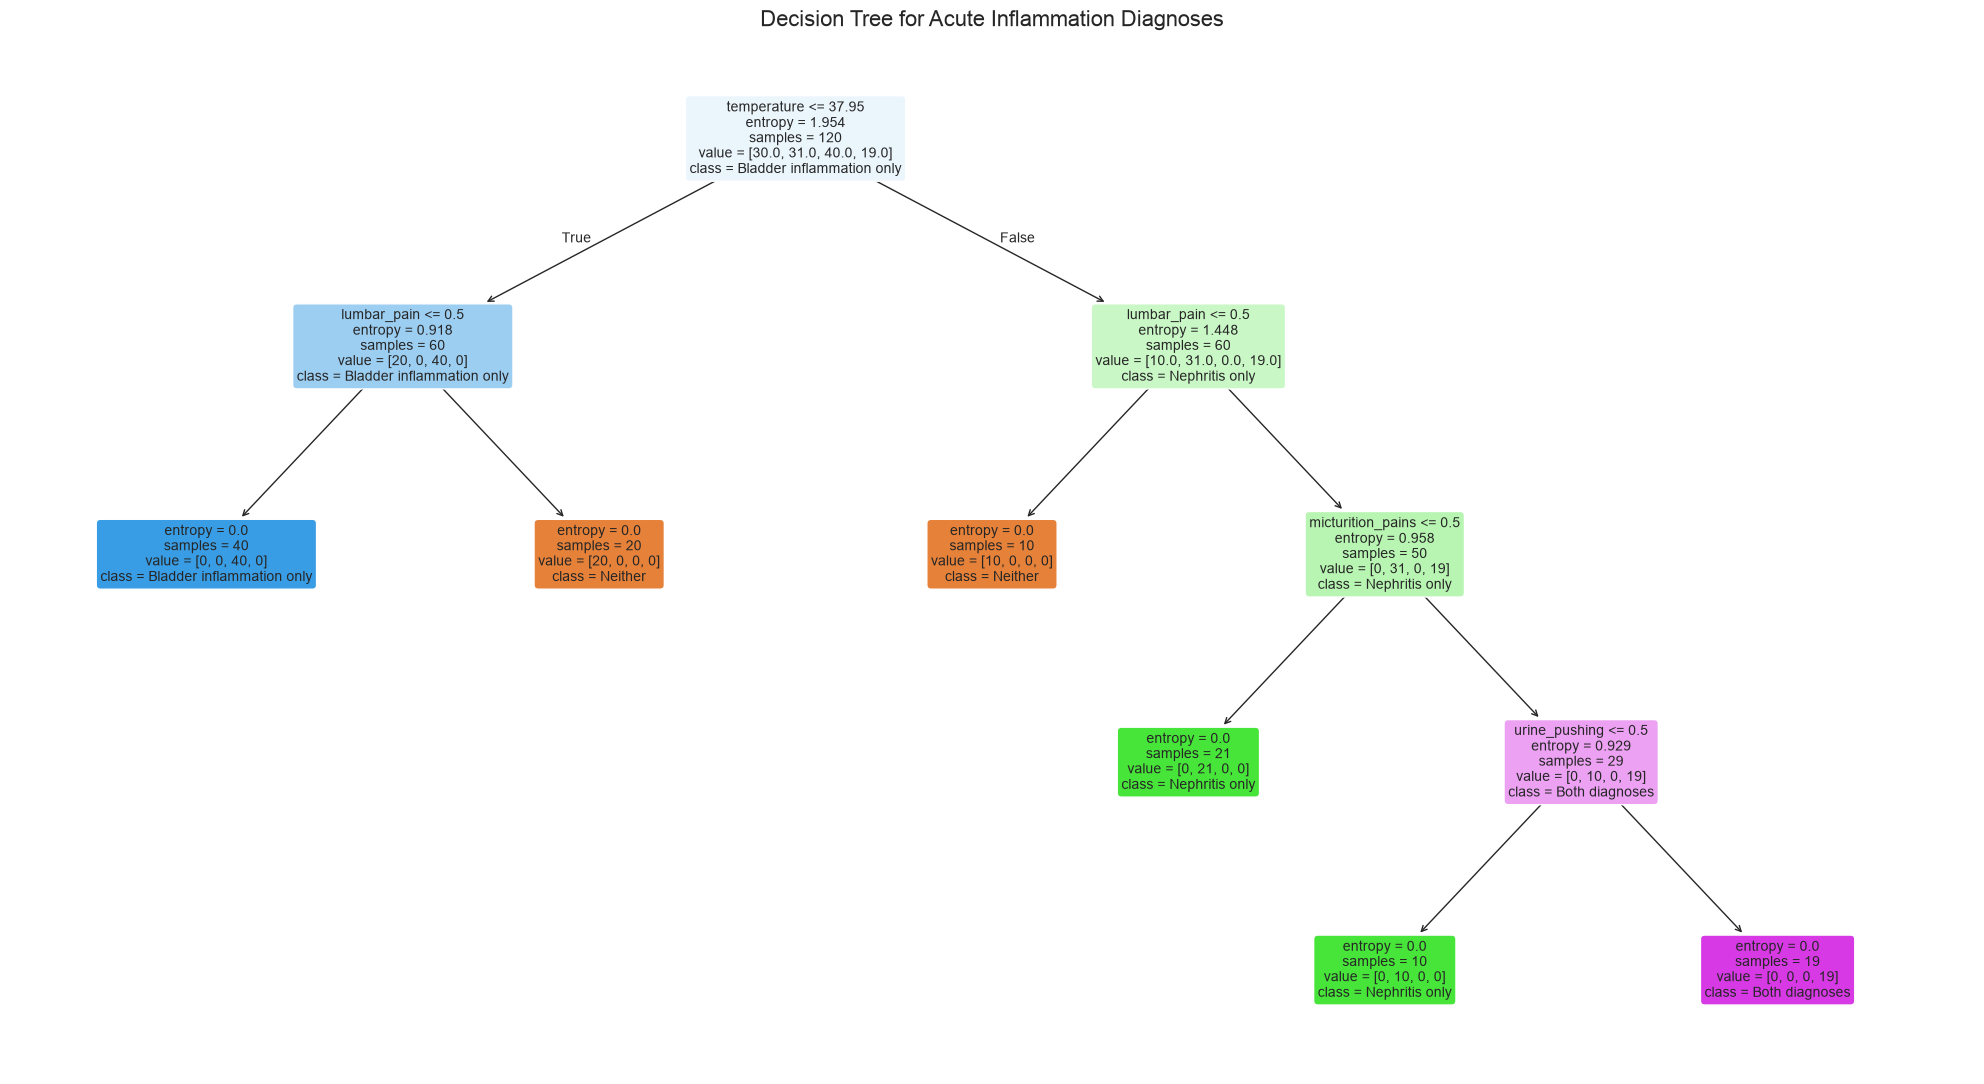

In [3]:
# sep 6 predictors from 2 diag labels
diagnosis_feature_names = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra"]
X_diagnosis = diagnosis_data[diagnosis_feature_names].copy()
y_diagnosis = diagnosis_data[["bladder_inflammation", "nephritis"]].copy()
y_powerset = y_diagnosis.astype(str).agg("_".join, axis=1) # combine 2 bin labels into one label-powerset class

class_name_map = {"0_0": "Neither", "0_1": "Nephritis only", "1_0": "Bladder inflammation only", "1_1": "Both diagnoses"}
print("Label-powerset class counts:")
display(y_powerset.map(class_name_map).value_counts().to_frame(name="Count"))

# build decision tree on the entire ds
full_tree = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
full_tree.fit(X_diagnosis, y_powerset)

# calc ds predictions and accuracy
full_tree_predictions = full_tree.predict(X_diagnosis)
full_tree_accuracy = accuracy_score(y_powerset, full_tree_predictions)
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())
print("Number of nodes:", full_tree.tree_.node_count)
print("Whole-dataset accuracy:", round(full_tree_accuracy, 4))

# create readable class names in the tree's class order
tree_class_names = [class_name_map[class_label] for class_label in full_tree.classes_]
plt.figure(figsize=(20, 11)) # plot complete decision tree

plot_tree(full_tree, feature_names=diagnosis_feature_names, class_names=tree_class_names, filled=True, rounded=True, impurity=True, proportion=False, fontsize=10)
plt.title("Decision Tree for Acute Inflammation Diagnoses", fontsize=16)
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [4]:
#follow each path from the root to leaf recursively
def recurse_if_then_rules(model, feature_names, class_map, node, conditions, rule_number):
    tree_structure = model.tree_
    feature_index = tree_structure.feature[node]
 
    if feature_index != -2:  # continue splitting if the current node is not a leaf
        feature_name = feature_names[feature_index]
        threshold = tree_structure.threshold[node]
        
        if feature_name != "temperature" and np.isclose(threshold, 0.5): # make binary conditions easier to interpret
            left_condition = f"{feature_name} = no"
            right_condition = f"{feature_name} = yes"
        else:
            left_condition = f"{feature_name} <= {threshold:.2f}"
            right_condition = f"{feature_name} > {threshold:.2f}"

        # recursive funcs
        rule_number = recurse_if_then_rules(model, feature_names, class_map, tree_structure.children_left[node], conditions + [left_condition], rule_number)
        rule_number = recurse_if_then_rules(model, feature_names, class_map, tree_structure.children_right[node], conditions + [right_condition], rule_number)

    # print the diagnosis when a leaf is reached
    else:
        class_index = np.argmax(tree_structure.value[node][0])
        class_code = model.classes_[class_index]
        diagnosis = class_map[class_code]
        sample_count = tree_structure.n_node_samples[node]
        print(
            f"Rule {rule_number}: IF "
            + " AND ".join(conditions)
            + f" THEN diagnosis = {diagnosis} "
            + f"(samples = {sample_count})"
        )
        rule_number += 1

    return rule_number


# start the recursive rule extraction at the root node
def print_if_then_rules(model, feature_names, class_map):
    recurse_if_then_rules(model=model, feature_names=feature_names, class_map=class_map, node=0, conditions=[], rule_number=1)

print("IF-THEN decision rules:\n")
print_if_then_rules(full_tree, diagnosis_feature_names, class_name_map)

IF-THEN decision rules:

Rule 1: IF temperature <= 37.95 AND lumbar_pain = no THEN diagnosis = Bladder inflammation only (samples = 40)
Rule 2: IF temperature <= 37.95 AND lumbar_pain = yes THEN diagnosis = Neither (samples = 20)
Rule 3: IF temperature > 37.95 AND lumbar_pain = no THEN diagnosis = Neither (samples = 10)
Rule 4: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = no THEN diagnosis = Nephritis only (samples = 21)
Rule 5: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = Nephritis only (samples = 10)
Rule 6: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = Both diagnoses (samples = 19)


### (d) Cost-complexity pruning

Cost-complexity pruning results:


,ccp_alpha,Mean CV Accuracy,CV Standard Deviation,Tree Depth,Number of Leaves,Number of Nodes
0,0.0000,1.0000,0.0000,4,6,11
1,0.1996,0.8667,0.0667,2,4,7
2,0.3250,0.7750,0.0726,2,3,5
3,0.4591,0.6083,0.0333,1,2,3
4,0.7704,0.3833,0.1000,0,1,1


Selected ccp_alpha: 0.0
Best mean CV accuracy: 1.0


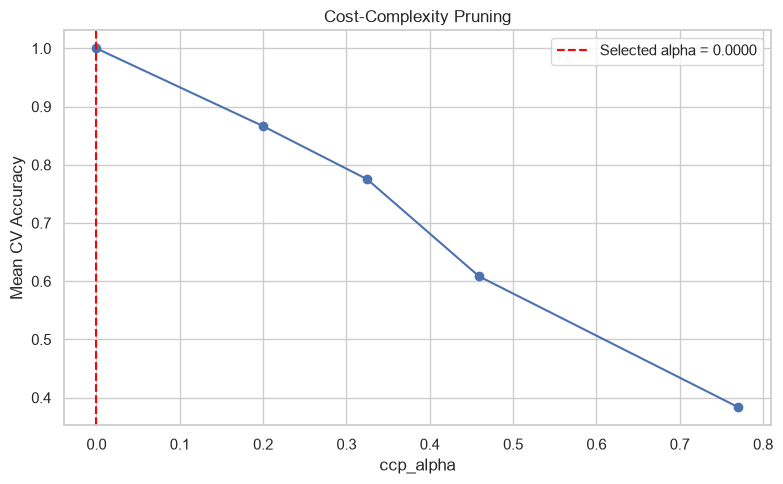

Minimal tree depth: 4
Minimal tree leaves: 6
Minimal tree nodes: 11
Whole-dataset accuracy: 1.0


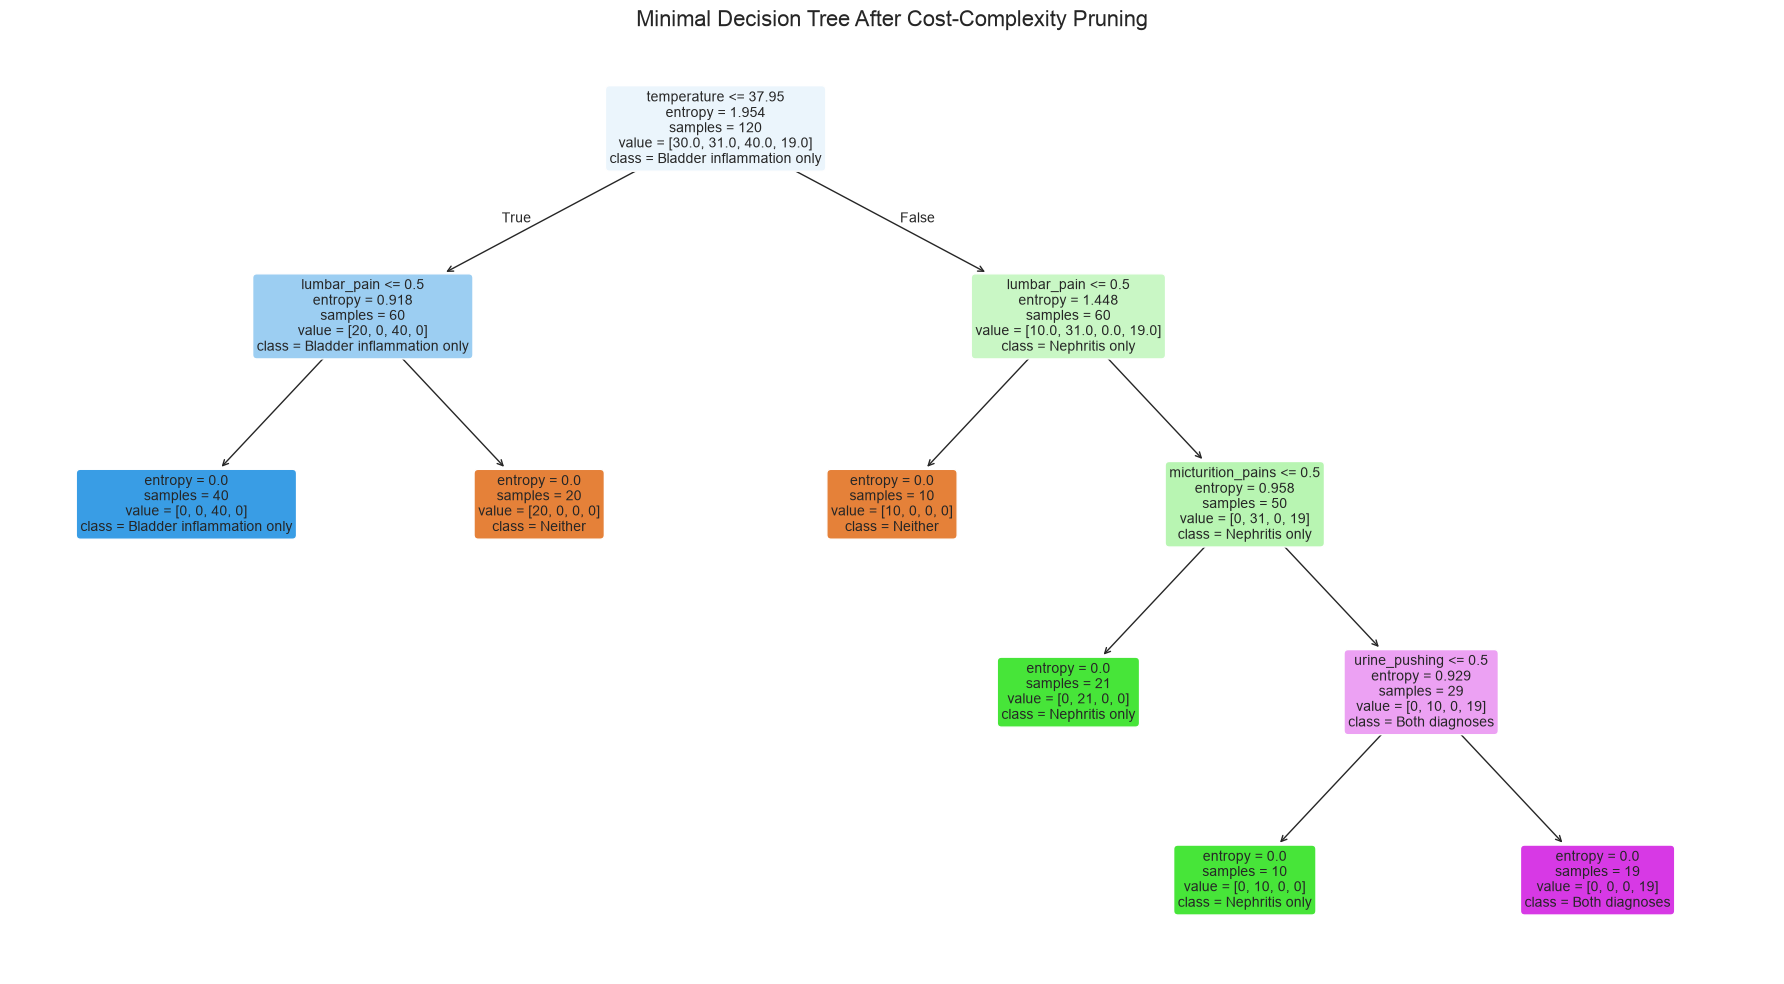

IF-THEN rules for the minimal tree:

Rule 1: IF temperature <= 37.95 AND lumbar_pain = no THEN diagnosis = Bladder inflammation only (samples = 40)
Rule 2: IF temperature <= 37.95 AND lumbar_pain = yes THEN diagnosis = Neither (samples = 20)
Rule 3: IF temperature > 37.95 AND lumbar_pain = no THEN diagnosis = Neither (samples = 10)
Rule 4: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = no THEN diagnosis = Nephritis only (samples = 21)
Rule 5: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = Nephritis only (samples = 10)
Rule 6: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = Both diagnoses (samples = 19)


In [5]:
from sklearn.model_selection import StratifiedKFold #keep four diagnosis classes represented in each fold

pruning_path = full_tree.cost_complexity_pruning_path(X_diagnosis, y_powerset)
candidate_alphas = pruning_path.ccp_alphas
pruning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# eval every available pruning strength
pruning_rows = []

for ccp_alpha in candidate_alphas:
    candidate_tree = DecisionTreeClassifier(criterion="entropy", ccp_alpha=ccp_alpha, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(candidate_tree, X_diagnosis, y_powerset, cv=pruning_cv, scoring="accuracy")

    candidate_tree.fit(X_diagnosis, y_powerset)

    pruning_rows.append(
        {
            "ccp_alpha": ccp_alpha,
            "Mean CV Accuracy": cv_scores.mean(),
            "CV Standard Deviation": cv_scores.std(),
            "Tree Depth": candidate_tree.get_depth(),
            "Number of Leaves": candidate_tree.get_n_leaves(),
            "Number of Nodes": candidate_tree.tree_.node_count
        }
    )

pruning_results = pd.DataFrame(pruning_rows)

print("Cost-complexity pruning results:")
display(pruning_results.round(4))
best_cv_accuracy = pruning_results["Mean CV Accuracy"].max() #largest alpha among the models tied for best cv acc
best_candidates = pruning_results[np.isclose(pruning_results["Mean CV Accuracy"], best_cv_accuracy)]
selected_alpha = best_candidates.sort_values("ccp_alpha").iloc[-1]["ccp_alpha"]
print("Selected ccp_alpha:", round(selected_alpha, 6))
print("Best mean CV accuracy:", round(best_cv_accuracy, 4))

plt.figure(figsize=(8, 5)) # cv accuracy for each pruning strength
plt.plot(pruning_results["ccp_alpha"], pruning_results["Mean CV Accuracy"], marker="o")
plt.axvline(selected_alpha, color="red", linestyle="--", label=f"Selected alpha = {selected_alpha:.4f}")
plt.xlabel("ccp_alpha")
plt.ylabel("Mean CV Accuracy")
plt.title("Cost-Complexity Pruning")
plt.legend()
plt.tight_layout()
plt.show()

# fit selected min tree on whole ds
minimal_tree = DecisionTreeClassifier(criterion="entropy", ccp_alpha=selected_alpha, random_state=RANDOM_STATE)
minimal_tree.fit(X_diagnosis, y_powerset)
minimal_tree_predictions = minimal_tree.predict(X_diagnosis)
minimal_tree_accuracy = accuracy_score(y_powerset, minimal_tree_predictions)
print("Minimal tree depth:", minimal_tree.get_depth())
print("Minimal tree leaves:", minimal_tree.get_n_leaves())
print("Minimal tree nodes:", minimal_tree.tree_.node_count)
print("Whole-dataset accuracy:", round(minimal_tree_accuracy, 4))

# plot selected minimal tree
minimal_class_names = [class_name_map[class_code] for class_code in minimal_tree.classes_]

plt.figure(figsize=(18, 10))
plot_tree(minimal_tree, feature_names=diagnosis_feature_names, class_names=minimal_class_names, filled=True, rounded=True, impurity=True, fontsize=10)
plt.title("Minimal Decision Tree After Cost-Complexity Pruning", fontsize=16)
plt.tight_layout()
plt.show()

print("IF-THEN rules for the minimal tree:\n")

print_if_then_rules(minimal_tree, diagnosis_feature_names, class_name_map)

#### Cost-Complexity Pruning Interpretation

The unpruned tree which corresponds to `ccp_alpha = 0` achieved the highest mean five-fold cross-validation accuracy of 1.0000. Every positive value of `ccp_alpha` reduced the tree size, but it also reduced cross-validation accuracy. For example, `ccp_alpha = 0.1996` reduced the tree from 11 to 7 nodes, but its mean cross-validation accuracy decreased to 0.8667.

Therefore, the selected value is `ccp_alpha = 0`. This means that no additional pruning is beneficial. The original tree is already compact and has a depth of 4, 6 leaves, 11 nodes, and only 6 IF-THEN rules. It's both perfectly accurate on the complete dataset and highly interpretable.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
communities_path = Path("../data/communities.data")
communities_names_path = Path("../data/communities.names")
community_attribute_names = [] #128 col names from the arff section of names file

with communities_names_path.open(encoding="latin-1") as names_file:
    for line in names_file:
        cleaned_line = line.strip()

        if cleaned_line.lower().startswith("@attribute"):
            attribute_name = cleaned_line.split()[1]
            community_attribute_names.append(attribute_name)

print("Number of attribute names:", len(community_attribute_names))

#convert ?s to missing vals
communities_data = pd.read_csv(communities_path, header=None, names=community_attribute_names, na_values="?")

assert communities_data.shape == (1994, 128) #verify complete ds
assert communities_data["ViolentCrimesPerPop"].isna().sum() == 0

print("Complete dataset shape:", communities_data.shape)
print("Total missing values:", communities_data.isna().sum().sum())

#first 1495 - training, rest testing
communities_train_raw = communities_data.iloc[:1495].copy()
communities_test_raw = communities_data.iloc[1495:].copy()

assert communities_train_raw.shape == (1495, 128)
assert communities_test_raw.shape == (499, 128)

print("Training-set shape:", communities_train_raw.shape)
print("Testing-set shape:", communities_test_raw.shape)

preview_columns = community_attribute_names[:10] + ["ViolentCrimesPerPop"]

print("\nFirst five rows:")
display(communities_data[preview_columns].head())

print("\nData type counts:")
display(communities_data.dtypes.value_counts().to_frame(name="Number of Columns"))

Number of attribute names: 128
Complete dataset shape: (1994, 128)
Total missing values: 39202
Training-set shape: (1495, 128)
Testing-set shape: (499, 128)

First five rows:


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.03



Data type counts:


,Number of Columns
float64,125
int64,2
str,1


### (b) Missing values

In [7]:
# remove 5 nonpred cols
nonpredictive_columns = ["state", "county", "community", "communityname", "fold"]
target_name = "ViolentCrimesPerPop"

# sep the preds and target after row split
X_communities_train_raw = communities_train_raw.drop(columns=nonpredictive_columns + [target_name])
X_communities_test_raw = communities_test_raw.drop(columns=nonpredictive_columns + [target_name])
y_communities_train = communities_train_raw[target_name].copy()
y_communities_test = communities_test_raw[target_name].copy()
community_feature_names = X_communities_train_raw.columns.tolist()

assert X_communities_train_raw.shape == (1495, 122)
assert X_communities_test_raw.shape == (499, 122)

print("Number of predictive features:", len(community_feature_names))
print("Training missing values before imputation:", X_communities_train_raw.isna().sum().sum())
print("Testing missing values before imputation:", X_communities_test_raw.isna().sum().sum())

# fts w most missing training vals
missing_summary = pd.DataFrame({"Training Missing": X_communities_train_raw.isna().sum(), "Testing Missing": X_communities_test_raw.isna().sum()})
missing_summary = missing_summary[missing_summary["Training Missing"] > 0].sort_values("Training Missing", ascending=False)

print("\nFeatures containing missing values:")
display(missing_summary)

community_imputer = SimpleImputer(strategy="median") # fit median imp using only train set
X_communities_train = pd.DataFrame(community_imputer.fit_transform(X_communities_train_raw), columns=community_feature_names, index=X_communities_train_raw.index)
X_communities_test = pd.DataFrame(community_imputer.transform(X_communities_test_raw), columns=community_feature_names, index=X_communities_test_raw.index)

assert X_communities_train.shape == (1495, 122)
assert X_communities_test.shape == (499, 122)
assert X_communities_train.isna().sum().sum() == 0
assert X_communities_test.isna().sum().sum() == 0

print("Training missing values after imputation:", X_communities_train.isna().sum().sum())
print("Testing missing values after imputation:", X_communities_test.isna().sum().sum())
print("Imputed training shape:", X_communities_train.shape)
print("Imputed testing shape:", X_communities_test.shape)

Number of predictive features: 122
Training missing values before imputation: 27633
Testing missing values before imputation: 9218

Features containing missing values:


,Training Missing,Testing Missing
PctPolicBlack,1256,419
PctPolicHisp,1256,419
LemasGangUnitDeploy,1256,419
LemasPctPolicOnPatr,1256,419
PolicOperBudg,1256,419
PolicCars,1256,419
PolicAveOTWorked,1256,419
NumKindsDrugsSeiz,1256,419
OfficAssgnDrugUnits,1256,419
PctPolicMinor,1256,419


Training missing values after imputation: 0
Testing missing values after imputation: 0
Imputed training shape: (1495, 122)
Imputed testing shape: (499, 122)


### (c) Plot a correlation matrix

Correlation matrix shape: (122, 122)


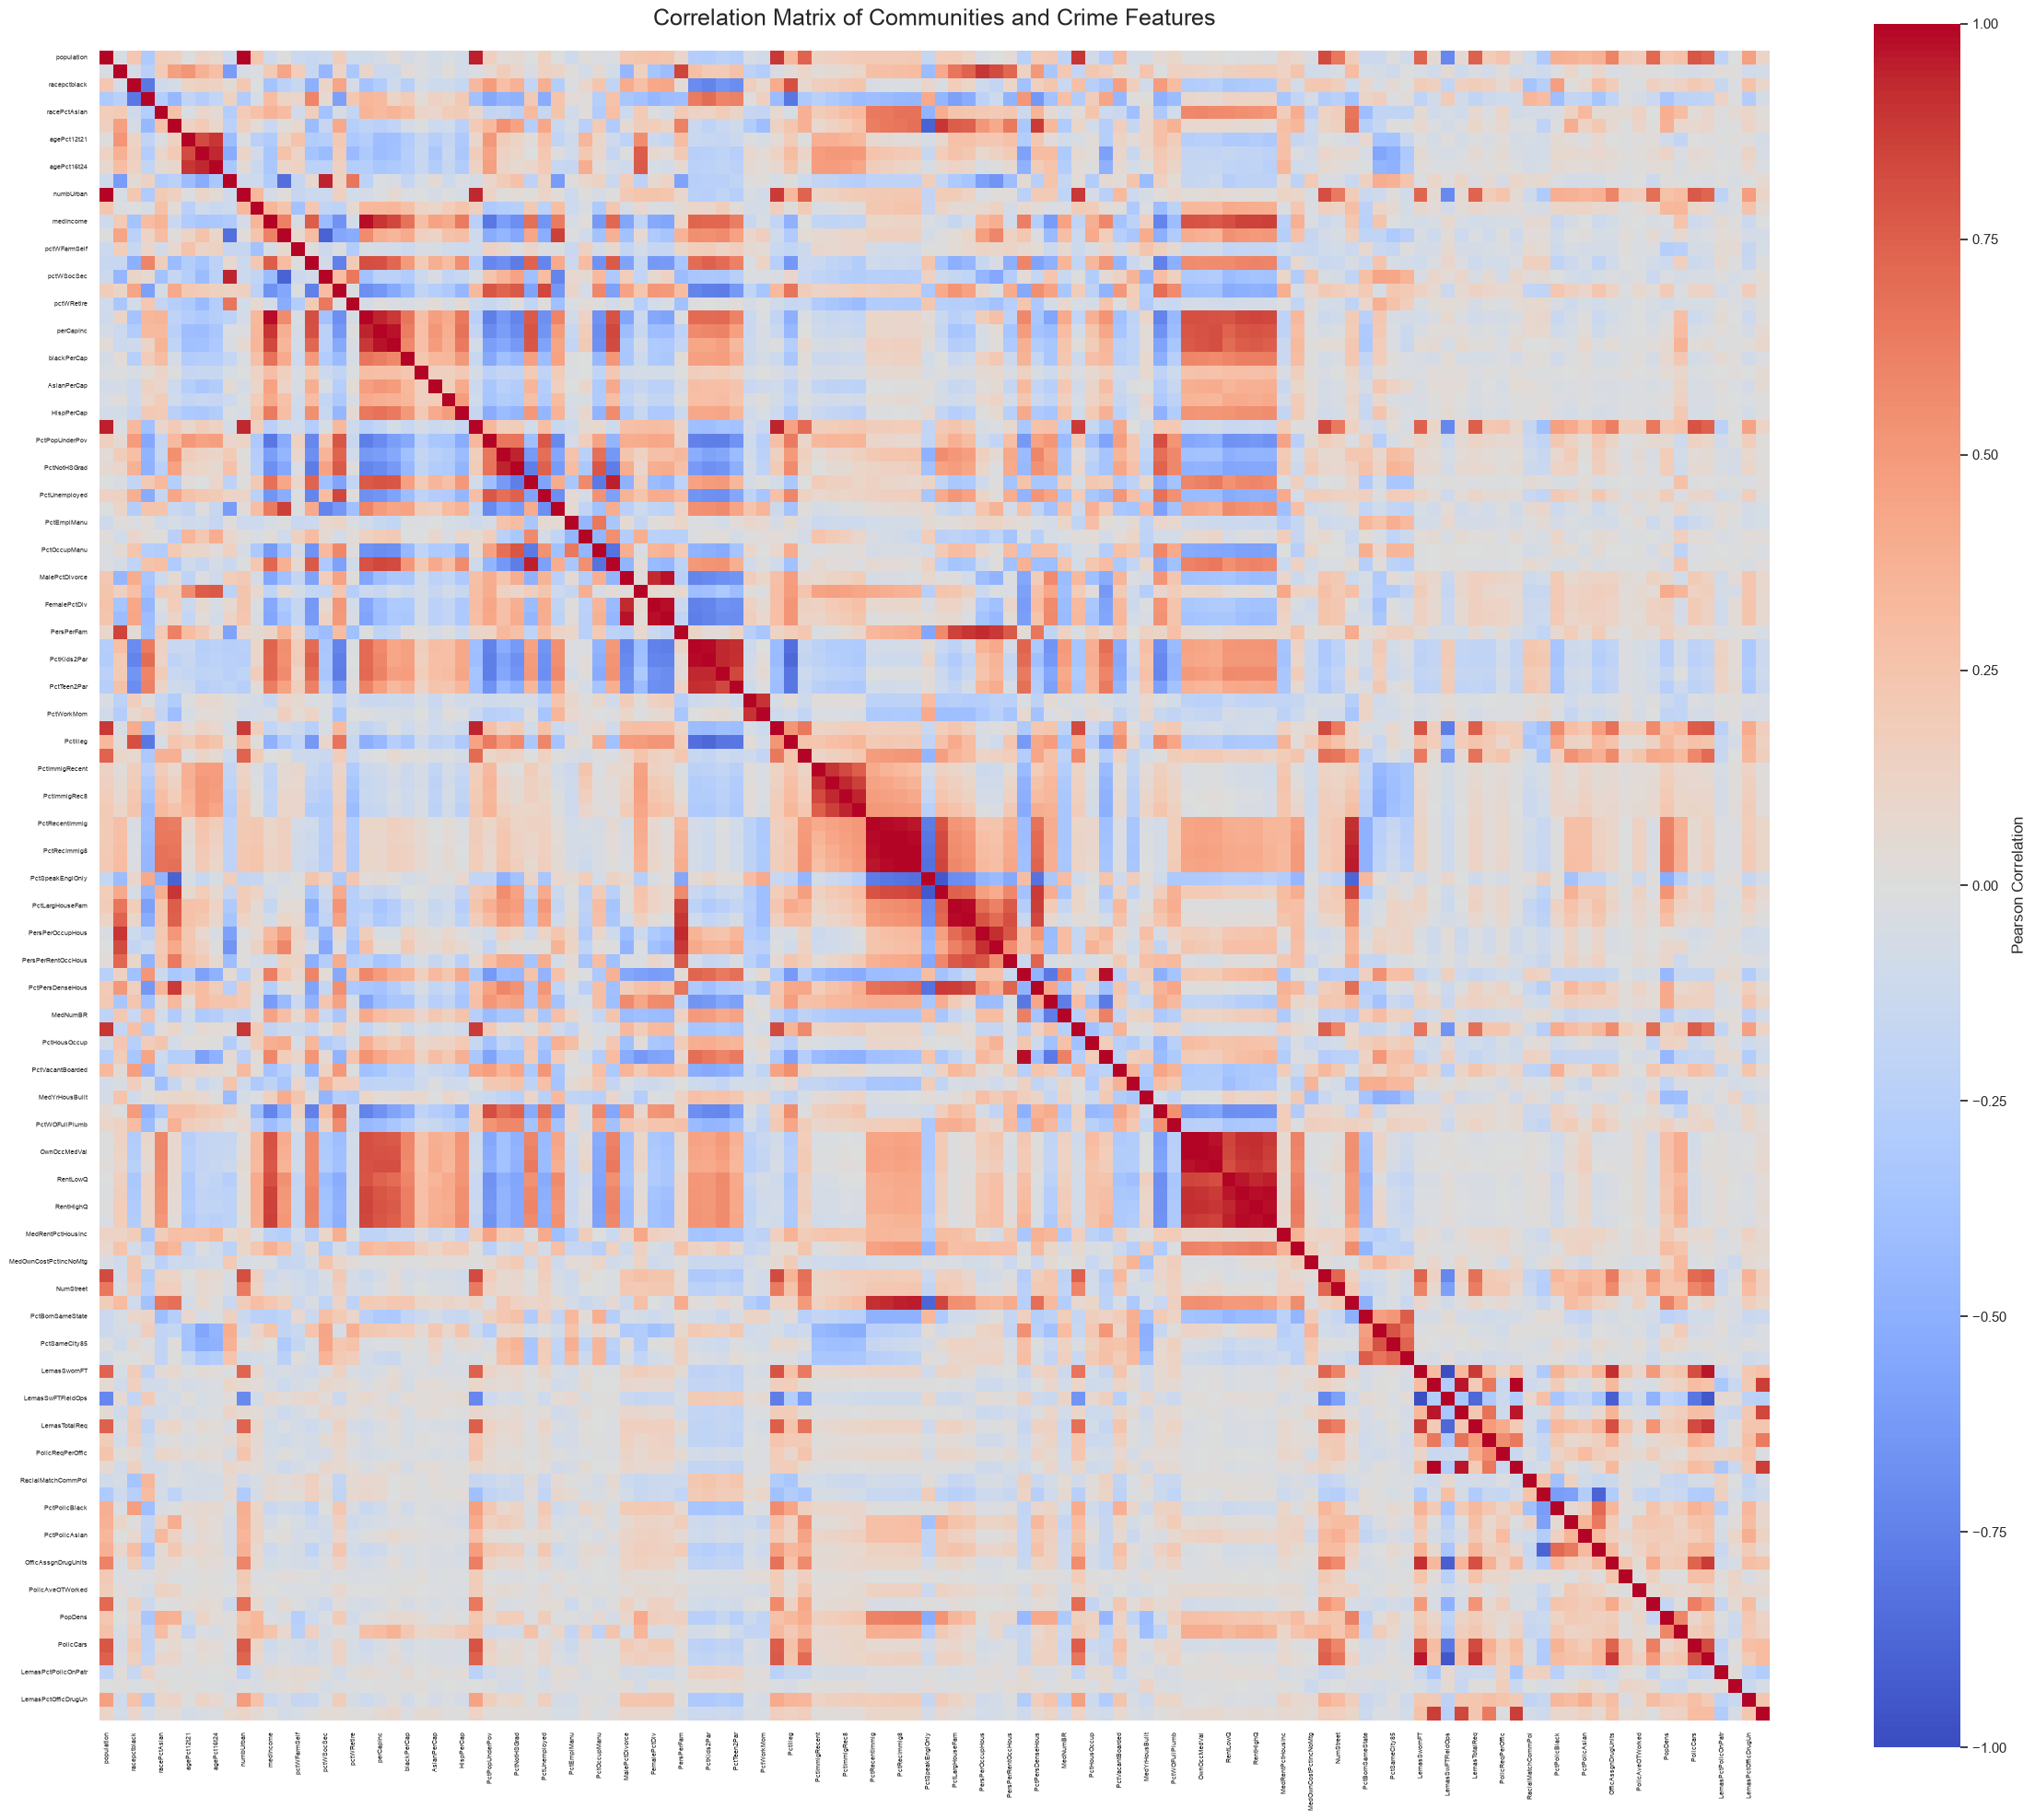

In [8]:
X_communities_all = pd.concat([X_communities_train, X_communities_test], axis=0).sort_index() #combine the imputed train and test preds analysis
assert X_communities_all.shape == (1994, 122)

# calculate correlations among all predictive features
community_correlation_matrix = X_communities_all.corr()

print("Correlation matrix shape:", community_correlation_matrix.shape)
plt.figure(figsize=(24, 20))
sns.heatmap(community_correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix of Communities and Crime Features", fontsize=18, pad=20)
plt.xticks(rotation=90, fontsize=5)
plt.yticks(rotation=0, fontsize=5)
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
community_feature_means = X_communities_all.mean() #calc mean and sample std dev for every ft
community_feature_sample_std = X_communities_all.std(ddof=1)

# calculate cv = sample std dev / mean
community_cv = (community_feature_sample_std / community_feature_means)

#table ranked from highest to lowest cv
community_cv_table = pd.DataFrame({"Mean": community_feature_means, "Sample Standard Deviation": community_feature_sample_std, "CV": community_cv}).sort_values("CV", ascending=False)

assert community_cv_table.shape == (122, 3)
assert np.isfinite(community_cv_table["CV"]).all()

print("Coefficient of Variation for all predictive features:")

with pd.option_context("display.max_rows", None):
    display(community_cv_table.round(4))

print("\nTop 11 features by CV:")
display(community_cv_table.head(11).round(4))

Coefficient of Variation for all predictive features:


,Mean,Sample Standard Deviation,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017



Top 11 features by CV:


,Mean,Sample Standard Deviation,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017


### (e) Scatter plots and box plots for highest CV features

### (f) Fit a linear model

### (g) Fit a ridge regression model

### (h) Fit a LASSO model

### (i) Fit a PCR model

### (j) Fit a boosting tree